# Vitaliza · Análise exploratória e segmentação da base
**Grupo 05 · MBA em IA e Dados para Negócios (Inteli) · Módulo 2 · entrega de 15/11/2026**

Este caderno refaz, a partir do código do projeto, a análise que sustenta o relatório de segmentação:

1. **A base**: quantos são os assinantes e como chegamos a eles.
2. **Raio-x**: centro, dispersão, extremos e correlações das principais variáveis.
3. **A escolha da segmentação**: os cenários de K-means comparados.
4. **Os 5 grupos**: quem são, quanto valem e quanto costumam sair.
5. **As 4 personas**: os números de cada uma.

Os números vêm dos mesmos scripts que geram o painel (`src/`). Os dados são fictícios, gerados para o curso; nenhum dado pessoal (e-mail, data de nascimento) aparece aqui.

**Como rodar:** com o projeto atualizado e a pasta `dados/processados` montada (passo a passo no README), abra este arquivo no Jupyter e use *Run All*.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ / 'src'))
PROC, SAIDAS = RAIZ / 'dados' / 'processados', RAIZ / 'saidas'
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.figsize': (9, 4.2), 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .3, 'font.size': 11})
pct = lambda v: f'{v:.1%}'.replace('.', ',')
print('Pastas do projeto encontradas:', PROC.exists() and SAIDAS.exists())

Pastas do projeto encontradas: True


## 1. A base: do cadastro ao assinante ativo

**O que vamos ver:** cada etapa do funil é uma população diferente. A segmentação usa a base de **assinantes pagantes ativos em 30/09/2026**, o corte do case.

,etapa,n
0,Contas criadas (até 30/09),64829
1,Começaram o teste grátis (desde 07/2024),46996
2,Pagaram alguma vez,32583
3,Pagantes ativos em 30/09,14753
4,"… sem saída anunciada (modelo, D-052)",12503


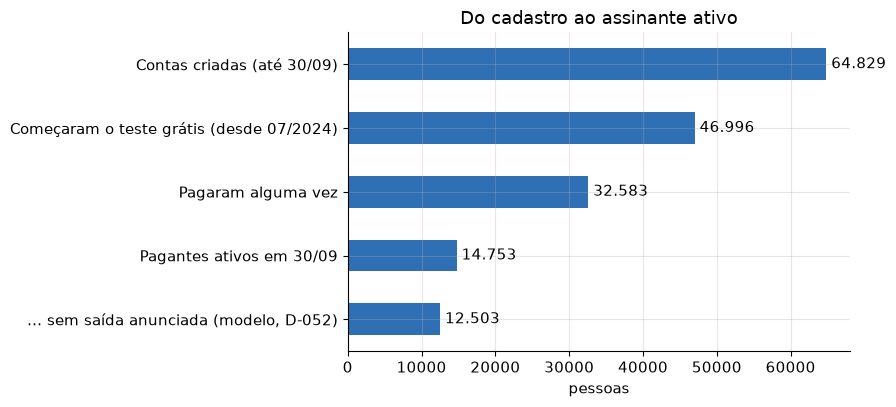

In [2]:
import raio_x
RX = raio_x.montar()          # mesmo cálculo da aba "Raio-x" do painel
funil = pd.DataFrame(RX['funil'])
display(funil)
ax = funil.iloc[::-1].plot.barh(x='etapa', y='n', legend=False, color='#2f6fb3')
ax.set_xlabel('pessoas'); ax.set_ylabel(''); ax.set_title('Do cadastro ao assinante ativo')
for i, v in enumerate(funil.n.iloc[::-1]): ax.text(v, i, f' {v:,}'.replace(',', '.'), va='center')
plt.tight_layout(); plt.show()

**Para o negócio:** das ~65 mil contas, só **14.753** pagam hoje, o número do enunciado. Cerca de 2.250 delas já desligaram a renovação; elas entram no retrato da base, mas seguem uma regra à parte no modelo de churn (D-052).

## 2. Raio-x: centro, dispersão e extremos

**O que vamos ver:** os cinco números (mínimo, quartis, máximo), a média e o coeficiente de variação das principais variáveis. Quando a média fica bem acima da mediana, alguns valores muito altos puxam a média (cauda à direita).

In [3]:
est = pd.DataFrame(RX['estatisticas']).set_index('variavel')
display(est.round(2))

,n,min,q1,mediana,q3,max,media,dp,cv,extremos_iqr,zeros
variavel,,,,,,,,,,,
Idade (anos),13856,18.0,39.0,46.0,55.0,74.0,47.49,11.08,0.23,0,0.00
Tempo de casa (meses),14753,0.0,4.0,8.6,18.2,72.7,13.73,15.22,1.11,1125,0.00
Treinos nas últimas 4 semanas,14753,0.0,3.0,8.0,13.0,57.0,8.84,7.10,0.80,227,0.12
Minutos de treino em 3 meses,14753,0.0,467.7,1031.8,1666.2,11634.8,1183.79,975.56,0.82,382,0.05
Dias desde o último treino,14577,0.0,0.0,2.0,7.0,271.0,12.78,32.66,2.56,2075,0.25
Aberturas do app no mês,14753,0.0,3.0,6.0,14.0,76.0,9.13,8.54,0.94,397,0.04
Seguidores na rede,14753,0.0,0.0,1.0,2.0,13.0,1.66,1.51,0.91,276,0.25
Posts em 90 dias,14753,0.0,0.0,1.0,2.0,9.0,1.50,1.38,0.92,189,0.27
Dias por semana declarados no onboarding,13262,1.0,2.0,3.0,4.0,7.0,3.52,1.48,0.42,0,0.00


**Para o negócio:** "dias desde o último treino" tem mediana baixa e média alta: a maioria treina toda semana, mas uma minoria parou há meses. Por isso, nas variáveis com cauda longa, a mediana descreve melhor o assinante típico, e o K-means precisa da variável transformada (log ou teto).

### Correlação entre as variáveis de uso

**O que vamos ver:** a correlação de Pearson (de −1 a +1) mostra quais variáveis andam juntas. Duas variáveis muito correlacionadas dizem quase a mesma coisa e, se entrassem juntas no K-means, contariam em dobro.

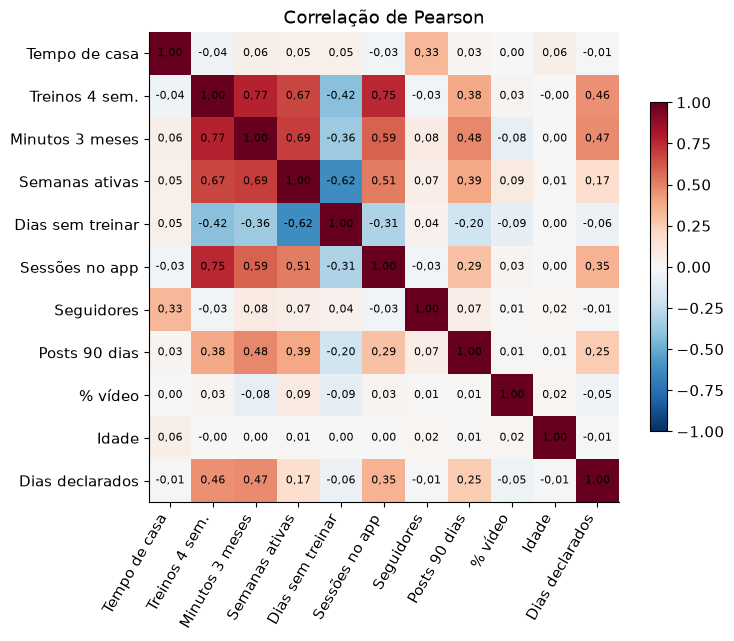

In [4]:
cor = pd.DataFrame(RX['correlacao']['matriz'], index=RX['correlacao']['nomes'], columns=RX['correlacao']['nomes'])
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(cor.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(cor)), cor.columns, rotation=60, ha='right'); ax.set_yticks(range(len(cor)), cor.index)
for i in range(len(cor)):
    for j in range(len(cor)):
        ax.text(j, i, f'{cor.values[i, j]:.2f}'.replace('.', ','), ha='center', va='center', fontsize=8)
ax.grid(False); fig.colorbar(im, shrink=.7); ax.set_title('Correlação de Pearson'); plt.tight_layout(); plt.show()

**Para o negócio:** treinos, minutos, semanas ativas e aberturas do app formam um bloco: "quanto a pessoa usa". Idade quase não se correlaciona com nada. Para a segmentação, escolhemos **uma** variável de cada bloco.

## 3. A escolha da segmentação (D-054)

**O que vamos ver:** rodamos o K-means na base ativa de 30/09 com todas as combinações de 3 a 6 variáveis (42) e de 3 a 7 grupos: 210 rodadas. Cada rodada tem três notas:
- **silhueta**: quão separados estão os grupos (0 = misturados, 1 = bem separados);
- **menor grupo**: precisa ter pelo menos 5% da base;
- **estabilidade**: concordância com outra semente e com um modelo treinado em metade da base (mínimo de 0,80).

A base é **normalizada** antes de cada rodada (teto no percentil 99, log no tempo de casa, mediana nos faltantes e `StandardScaler`). Nenhuma informação de saída entra no cálculo.

42 combinações · 210 rodadas · 166 aceitas


,n_vars,variaveis,k,silhueta,menor_grupo,estavel
37,3,mensal+min_por_treino+pct_ar_livre,5,0.665,0.058,1.000
133,4,mensal+treinos_semana+min_por_treino+pct_ar_livre,6,0.438,0.053,0.978
199,5,mensal+treinos_semana+min_por_treino+pct_ar_li...,7,0.315,0.050,0.961
209,6,mensal+tempo_casa+treinos_semana+min_por_trein...,7,0.241,0.048,0.960


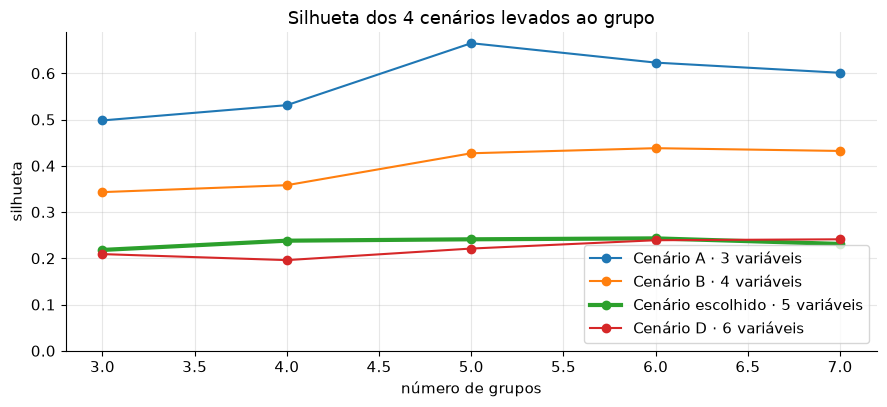

In [5]:
cen = pd.read_csv(SAIDAS / 'clusters_cenarios.csv')     # gerado por src/clusters_cenarios.py
print(f"{cen.variaveis.nunique()} combinações · {len(cen)} rodadas · {cen.aceito.sum()} aceitas")
display(cen.sort_values('silhueta', ascending=False).drop_duplicates('n_vars')[['n_vars', 'variaveis', 'k', 'silhueta', 'menor_grupo', 'estavel']])
P = json.loads((SAIDAS / 'clusters_perfis.json').read_text(encoding='utf-8'))
fig, ax = plt.subplots()
for c in P['cenarios']:
    s = pd.DataFrame(c['silhueta_por_k'])
    nome = 'Cenário escolhido' if c['cenario'] == 'C' else 'Cenário ' + c['cenario']
    ax.plot(s.k, s.silhueta, marker='o', lw=3 if c['cenario'] == 'C' else 1.5, label=f"{nome} · {c['n_vars']} variáveis")
ax.set_xlabel('número de grupos'); ax.set_ylabel('silhueta'); ax.set_ylim(0); ax.legend(); ax.set_title('Silhueta dos 4 cenários levados ao grupo')
plt.tight_layout(); plt.show()

**Para o negócio:** a silhueta cai quando entram mais variáveis, e o plano (0 ou 1) infla a silhueta dos cenários que o usam, porque divide a base em "mensal × anual", algo que já sabíamos. O grupo escolheu o **cenário escolhido** (5 variáveis de comportamento, sem o plano, 5 grupos): é o único que isola os novatos, é estável (0,95) e gera grupos que cabem numa frase. Processo completo em `saidas/clusters_cenarios.md` e na D-054.

## 4. Os 5 grupos

**O que vamos ver:** o "DNA" de cada grupo, ou seja, o centro do grupo nas 5 variáveis do cálculo, na escala padronizada (0 = média da base).

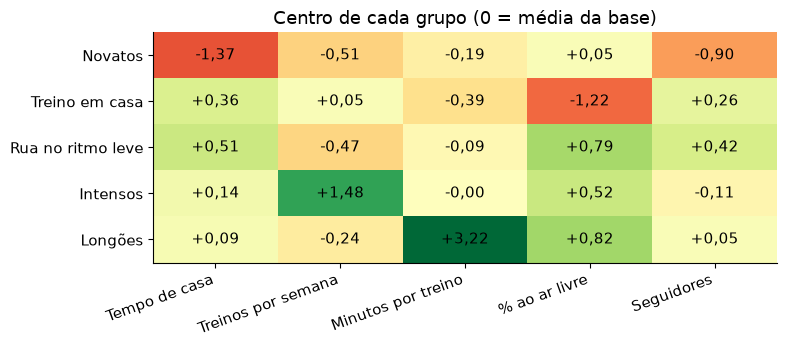

,% base,tempo_casa_meses,treinos_semana,min_por_treino,pct_ar_livre,seguidores,idade,% mensal
nome,,,,,,,,
Novatos,"20,3%",1.3,1.08,43.2,0.71,0.0,46.0,"57,6%"
Treino em casa,"29,8%",11.4,2.00,41.5,0.15,2.0,47.0,"43,1%"
Rua no ritmo leve,"28,2%",13.2,1.38,45.5,0.81,2.0,47.0,"29,4%"
Intensos,"16,0%",9.2,3.85,45.4,0.79,1.0,46.0,"49,1%"
Longões,"5,7%",9.8,1.46,83.7,0.82,1.0,46.0,"32,1%"


In [6]:
S = json.loads((SAIDAS / 'clusters_final.json').read_text(encoding='utf-8'))   # gerado por src/clusters.py
G = pd.DataFrame(S['grupos']).set_index('nome')
z = pd.DataFrame(G.centro_z.tolist(), index=G.index).rename(columns=S['nomes_vars'])
fig, ax = plt.subplots(figsize=(8, 3.6))
im = ax.imshow(z.values, cmap='RdYlGn', vmin=-2, vmax=2, aspect='auto')
ax.set_xticks(range(z.shape[1]), z.columns, rotation=20, ha='right'); ax.set_yticks(range(len(z)), z.index)
for i in range(z.shape[0]):
    for j in range(z.shape[1]):
        ax.text(j, i, f'{z.values[i, j]:+.2f}'.replace('.', ','), ha='center', va='center')
ax.grid(False); ax.set_title('Centro de cada grupo (0 = média da base)'); plt.tight_layout(); plt.show()
med = pd.DataFrame(G.mediana.tolist(), index=G.index)
med.insert(0, '% base', G.pct.map(pct)); med['% mensal'] = [pct(p['mensal']) for p in G.plano]
display(med)

**Para o negócio:** cada grupo é marcado por uma ou duas variáveis. Os **novatos** se definem pelo pouco tempo de casa e pela falta de seguidores; o **treino em casa**, pelo % ao ar livre baixo; os **intensos**, pela frequência; os **longões**, pela duração do treino. A **rua no ritmo leve** é o "centro" da base: veterana, de rua, com frequência abaixo da média.

### O que ficou fora do cálculo muda entre os grupos?

**O que vamos ver:** plano, objetivo do cadastro e canal de aquisição **não** entraram no K-means. Se eles variam de forma coerente entre os grupos, é sinal de que os grupos são reais.

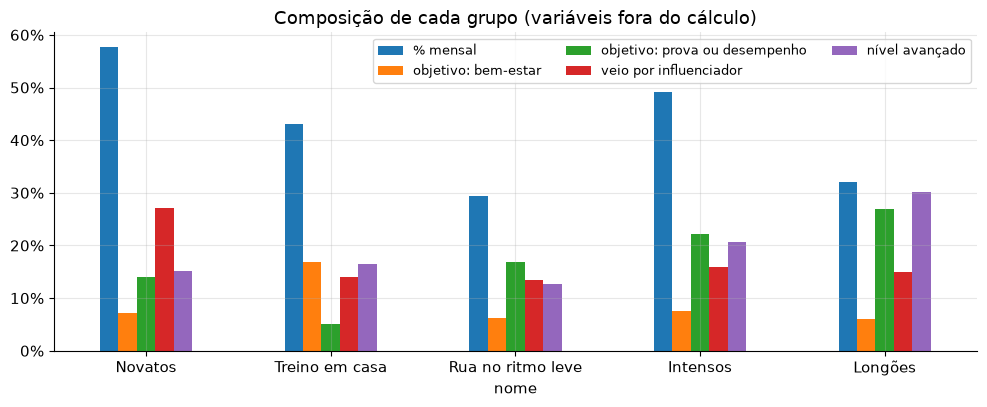

In [7]:
comp = pd.DataFrame({
    '% mensal': [p['mensal'] for p in G.plano],
    'objetivo: bem-estar': [o['bem_estar'] for o in G.objetivo],
    'objetivo: prova ou desempenho': [o['prova_com_prazo'] + o['desempenho'] for o in G.objetivo],
    'veio por influenciador': [c['influenciador'] for c in G.canal_aquisicao],
    'nível avançado': [n['avancado'] for n in G.nivel],
}, index=G.index)
ax = comp.plot.bar(figsize=(10, 4.2), rot=0); ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
ax.set_title('Composição de cada grupo (variáveis fora do cálculo)'); ax.legend(ncol=3, fontsize=9); plt.tight_layout(); plt.show()

**Para o negócio:** os novatos são mais mensais e o dobro dos outros veio por influenciador; o treino em casa concentra o objetivo de bem-estar; intensos e longões são os mais avançados e os mais focados em prova. Idade, sexo e relógio, por outro lado, são iguais em todos os grupos: a mensagem deve mudar por **comportamento**, não por perfil demográfico.

### Tamanho, valor e saída

**O que vamos ver:** a saída em 60 dias de cada grupo. Em 30/09 ainda não sabemos quem vai sair, então aplicamos **a mesma régua de 30/09** às variáveis montadas em **31/05/2026** e medimos quem desligou a renovação ou cancelou pelo site nos 60 dias seguintes (D-053), sem quem já tinha anunciado a saída (D-052). A saída **não** entrou na formação dos grupos; ela só os descreve.

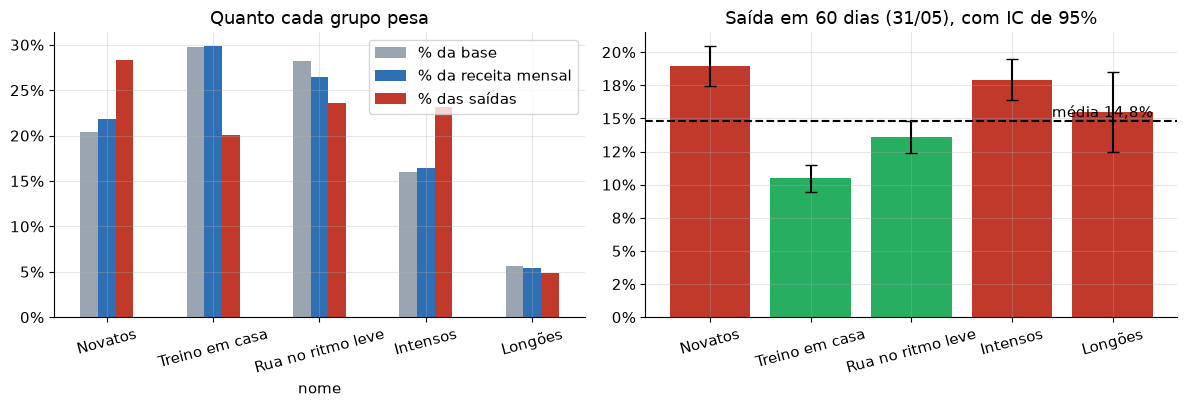

,saída,mensal,anual,% das saídas,n (31/05)
nome,,,,,
Novatos,"19,0%","22,0%","14,8%","28,3%",2645
Treino em casa,"10,5%","13,6%","7,5%","20,0%",3390
Rua no ritmo leve,"13,6%","18,2%","10,9%","23,6%",3082
Intensos,"17,9%","21,6%","14,4%","23,2%",2292
Longões,"15,5%","17,4%","14,2%","4,9%",556


In [8]:
H = pd.DataFrame(G.historico.tolist(), index=G.index)
base = S['historico']['taxa_base']
peso = pd.DataFrame({'% da base': G.pct, '% da receita mensal': [v['mrr_pct'] for v in G.valor], '% das saídas': H.pct_dos_desligamentos})
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
peso.plot.bar(ax=axs[0], rot=15, color=['#9aa5b1', '#2f6fb3', '#c0392b']); axs[0].yaxis.set_major_formatter(lambda v, _: f'{v:.0%}'); axs[0].set_title('Quanto cada grupo pesa')
err = np.array([[t - lo for t, (lo, hi) in zip(H.taxa, H.ic95)], [hi - t for t, (lo, hi) in zip(H.taxa, H.ic95)]])
axs[1].bar(H.index, H.taxa, yerr=err, capsize=4, color=['#c0392b' if t > base else '#27ae60' for t in H.taxa])
axs[1].axhline(base, ls='--', color='k'); axs[1].text(4.4, base, f' média {pct(base)}', va='bottom', ha='right')
axs[1].yaxis.set_major_formatter(lambda v, _: f'{v:.0%}'); axs[1].set_title('Saída em 60 dias (31/05), com IC de 95%'); axs[1].tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.show()
display(pd.DataFrame({'saída': H.taxa.map(pct), 'mensal': H.mensal_taxa.map(pct), 'anual': H.anual_taxa.map(pct), '% das saídas': H.pct_dos_desligamentos.map(pct), 'n (31/05)': H.n}))

**Para o negócio:** a saída vai de **10,5%** (treino em casa) a **19,0%** (novatos), e os intervalos de confiança dos extremos não se tocam: a diferença é real. Os novatos são 20% da base e 28% das saídas. A surpresa são os **intensos** (17,9%): treinar muito não garante ficar.

### O que pesa na saída dentro de cada grupo

**O que vamos ver:** dentro de cada grupo, a saída de quem tinha um sinal × a de quem não tinha (31/05). Cruzamento aponta suspeitos, não prova causa.

In [9]:
linhas = [{'grupo': n, 'sinal': d['sinal'], '% do grupo': pct(d['pct_grupo']), 'com o sinal': pct(d['taxa_com']), 'sem o sinal': pct(d['taxa_sem']),
           'diferença (p.p.)': round((d['taxa_com'] - d['taxa_sem']) * 100, 1)} for n, g in G.iterrows() for d in g.drivers[:3]]
display(pd.DataFrame(linhas).set_index(['grupo', 'sinal']))

% do grupo com o sinal sem o sinal  diferença (p.p.)
grupo             sinal                                                                                
Novatos           Chamado técnico (90 dias)              4,1%       35,8%       18,3%              17.5
                  Plano mensal                          58,5%       22,0%       14,8%               7.2
                  Treino caiu forte (4 semanas)          7,3%       24,9%       18,5%               6.3
Treino em casa    14+ dias sem treinar                   6,6%       19,6%        9,8%               9.8
                  Plano mensal                          48,6%       13,6%        7,5%               6.1
                  Pagava o preço antigo (reajuste)      45,2%       13,7%        7,8%               5.8
Rua no ritmo leve Treino caiu forte (4 semanas)         11,6%       22,6%       12,4%              10.2
                  Chamado técnico (90 dias)              6,3%       21,2%       13,1%               8.2
                  Plano mensal                          37,1%       18,2%       10,9%               7.3
Intensos          Treino caiu forte (4 semanas)          7,9%       28,3%       17,1%              11.3
                  Chamado técnico (90 dias)             11,3%       24,7%       17,1%               7.6
                  Plano mensal                          49,1%       21,6%       14,4%               7.2
Longões           Nenhum seguidor                       22,8%       24,4%       12,8%              11.6
                  Chamado técnico (90 dias)              7,2%       25,0%       14,7%              10.3
                  Anual que renova nos 60 dias           7,6%       19,1%       15,2%               3.9

**Para o negócio:** a **queda forte no treino** é o alarme dos veteranos (rua no ritmo leve e intensos); no treino em casa, o sinal é **parar 14 dias ou mais**; nos longões, **não ter nenhum seguidor**. O chamado técnico pesava muito em maio, mas quase sumiu em setembro.

### A segmentação é confiável?

In [10]:
q = S['qualidade']
print(f"Silhueta média: {q['silhueta']:.2f} · concordância com outra semente: {q['ari_semente']:.2f} · com metade da base: {q['ari_metade']:.2f}")
display(pd.DataFrame({'% base em 30/09': G.pct.map(pct), '% base em 31/05 (mesma régua)': H.pct_base_31_05.map(pct), 'silhueta': G.silhueta}))

Silhueta média: 0.24 · concordância com outra semente: 0.99 · com metade da base: 0.95


,% base em 30/09,% base em 31/05 (mesma régua),silhueta
nome,,,
Novatos,"20,3%","20,8%",0.275
Treino em casa,"29,8%","27,9%",0.266
Rua no ritmo leve,"28,2%","28,4%",0.224
Intensos,"16,0%","17,2%",0.186
Longões,"5,7%","5,7%",0.241


**Para o negócio:** os grupos se repetem (95% a 99%) quando mudamos o sorteio inicial ou usamos só metade da base, e têm tamanhos parecidos em duas datas diferentes. A silhueta de 0,24 indica grupos que se tocam nas bordas, o que é comum em dados de clientes.

## 5. As 4 personas (D-055)

**O que vamos ver:** os 5 grupos viram 4 personas ("O atleta" junta intensos e longões). Para cada uma, a saída, o peso e quantas pessoas estão **hoje** com o sinal de alerta da persona (sem quem já anunciou a saída).

,grupos,% base,saída 60d,% das saídas,% receita mensal,com gatilho hoje,gatilho
persona,,,,,,,
O novato que ainda está chegando,Novatos,"20,3%","19,0%","28,3%","21,8%",182,treino caiu forte nas últimas 4 semanas (ou ch...
Quem treina em casa,Treino em casa,"29,8%","10,5%","20,0%","29,9%",194,14+ dias sem treinar (ainda treinou em 2026)
O corredor de rua no ritmo leve,Rua no ritmo leve,"28,2%","13,6%","23,6%","26,5%",365,treino caiu forte nas últimas 4 semanas (ou ch...
O atleta,Intensos + Longões,"21,6%","17,4%","28,0%","21,9%",308,"treino caiu forte, chamado técnico ou post de ..."


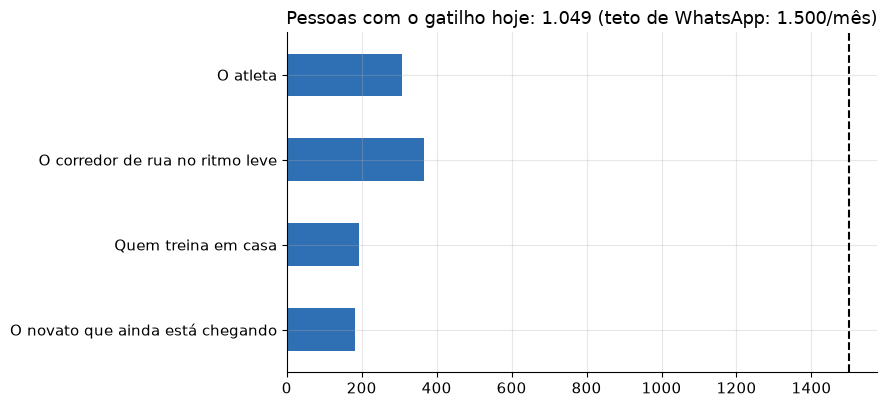

In [11]:
PE = json.loads((SAIDAS / 'personas.json').read_text(encoding='utf-8'))   # gerado por src/personas.py
tab = pd.DataFrame([{'persona': p['persona'], 'grupos': ' + '.join(p['grupos']), '% base': pct(p['pct']), 'saída 60d': pct(p['saida']),
                     '% das saídas': pct(p['pct_das_saidas']), '% receita mensal': pct(p['mrr_pct']), 'com gatilho hoje': p['gatilho']['n'],
                     'gatilho': p['gatilho']['regra']} for p in PE['personas']]).set_index('persona')
display(tab)
ax = tab['com gatilho hoje'].plot.barh(color='#2f6fb3'); ax.axvline(1500, ls='--', color='k')
ax.set_title(f"Pessoas com o gatilho hoje: {tab['com gatilho hoje'].sum():,} (teto de WhatsApp: 1.500/mês)".replace(',', '.')); ax.set_ylabel('')
plt.tight_layout(); plt.show()

**Para o negócio:** somados, os gatilhos de hoje são cerca de 1.050 pessoas, dentro do teto de 1.500 WhatsApps por mês; o resto da base recebe só push e e-mail. A prioridade preliminar é **agir já** no novato e no atleta, **monitorar** o corredor de rua no ritmo leve e **proteger** quem treina em casa. Os cartões completos estão em `docs/personas.md`.

## Limites

- A saída é a de 31/05 medida com a régua de 30/09: uma pessoa pode ter mudado de grupo entre as datas.
- Cruzamentos apontam suspeitos, não provam causa; o único experimento sorteado da base é a campanha de agosto.
- Receita mensal estimada pelo preço de tabela e pela taxa de cada canal (cupons não descontados).
- O resumo mensal de uso e o detalhe de treinos discordam em 2026 (D-029); usamos o detalhe dos treinos.
- Textos (objetivo, posts) foram lidos por palavras-chave; a leitura com IA generativa vem no objetivo 5.